# Pandas 探索与 NumPy 文本特征
探索统计与词表只从训练邮件形成，和网页共用分析函数。

In [1]:
from pathlib import Path
import os,json
if not Path('configs').exists() and Path('../configs').exists():os.chdir('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from spam_analysis.analysis.results import source_records,result_table,error_frame
from spam_analysis.experiments.runtime import ExperimentSession
plt.rcParams['font.sans-serif']=['Microsoft YaHei']
plt.rcParams['axes.unicode_minus']=False
engine=ExperimentSession()
print('结果版本：',engine.run_id)


结果版本： course-20261016


In [2]:
train=source_records('combined','train')
display(train.groupby(['source_id','label']).agg(邮件数=('doc_id','size'),长度均值=('body_chars','mean'),长度中位数=('body_chars','median'),P90=('body_chars',lambda s:s.quantile(.9))))
display(pd.crosstab(train.label,train.url_count.gt(0),normalize='index'))

邮件数         长度均值   长度中位数     P90
source_id    label                                    
enron        0       8698  1575.991147   724.0  2926.6
             1      12708  1193.300834   592.0  2926.3
spamassassin 0       2058  1695.690962   966.5  3423.9
             1        875  2370.819429  1042.0  4192.2
trec06c      0      11955   638.005102   284.0   940.0
             1      24203   854.057637   364.0  2244.0

url_count,False,True
label,,
0,0.856457,0.143543
1,0.539009,0.460991


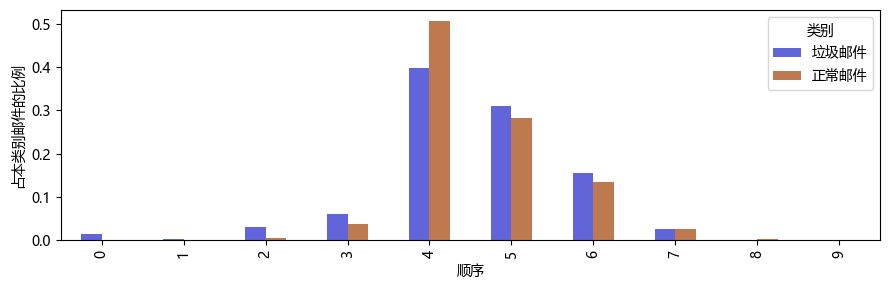

,类别,区间,顺序,邮件数,类内比例,分母
0,正常邮件,"[0, 3)",0,5,0.000220,22711
1,正常邮件,"[3, 11)",1,18,0.000793,22711
2,正常邮件,"[11, 37)",2,113,0.004976,22711
3,正常邮件,"[37, 127)",3,867,0.038175,22711
4,正常邮件,"[127, 429)",4,11495,0.506142,22711


In [3]:
from spam_analysis.analysis.distributions import grouped_distribution
distribution=grouped_distribution(train,'body_chars')
assert distribution.groupby('类别')['邮件数'].sum().sum()==len(train)
chart=distribution.pivot(index='顺序',columns='类别',values='类内比例')
chart.plot.bar(figsize=(9,3),color=['#6265d9','#be794f']);plt.ylabel('占本类别邮件的比例');plt.tight_layout();plt.show()
display(distribution.head())

In [4]:
from spam_analysis.analysis.distributions import corpus_terms
terms=corpus_terms(train)
display(pd.concat([terms.nlargest(6,'spam_minus_ham'),terms.nsmallest(6,'spam_minus_ham')]))

,term,ham_rate,spam_rate,spam_minus_ham
2014,com,0.182863,0.607871,0.425008
12666,公司,0.041258,0.399513,0.358256
18362,有限公司,0.007177,0.300164,0.292987
4756,http,0.125710,0.406182,0.280472
16776,您好,0.000925,0.262478,0.261554
13872,发票,0.000528,0.227412,0.226884
6675,on,0.296156,0.128222,-0.167934
10563,一个,0.277355,0.112634,-0.164720
3412,enron,0.164414,0.000000,-0.164414
19076,没有,0.237858,0.075001,-0.162857


每封邮件只计一次词语出现。比较类内比例，避免类别数量影响；常见词不一定更有区分力，关联也不等于因果。

In [5]:
from spam_analysis.teaching import tfidf_lesson
lesson=tfidf_lesson()
for key in ['documents','vocabulary','counts','document_frequency','idf','tfidf','cosine_matrix']:
    print(key);display(lesson[key])
assert lesson['sklearn_equal']

documents


['课程 通知 课程', '免费 优惠', '课程 作业 通知', '免费 课程 优惠']

vocabulary


['优惠', '作业', '免费', '课程', '通知']

counts


...

array([1.51082562, 1.91629073, 1.51082562, 1.22314355, 1.51082562])

tfidf


array([[0.        , 0.        , 0.        , 0.8508161 , 0.52546357],
       [0.70710678, 0.        , 0.70710678, 0.        , 0.        ],
       [0.        , 0.70203482, 0.        , 0.44809973, 0.55349232],
       [0.61366674, 0.        , 0.61366674, 0.49681612, 0.        ]])

cosine_matrix


array([[1.        , 0.        , 0.67209051, 0.42269915],
       [0.        , 1.        , 0.        , 0.86785583],
       [0.67209051, 0.        , 1.        , 0.22262317],
       [0.42269915, 0.86785583, 0.22262317, 1.        ]])

教学例采用计数 TF、平滑 IDF 和 L2 归一化。正式词模型启用 sublinear TF，即非零计数使用 1+ln(count)，二者设置不同。